[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Buffers, Overlays and Clipping &middot; Solutions


One way to do each task. Not the only way. If yours runs and does what was asked, yours is
right too.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)

named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

districts = forecast_districts()
print("geopandas", gpd.__version__, "|", len(stations), "made-up stations,", len(named), "named stations,",
      len(districts), "made-up districts")

geopandas 1.2.0 | 300 made-up stations, 5 named stations, 8 made-up districts


The worked examples' layers in meters, rebuilt here so that each answer runs on its own. The stations and the districts are made up.

In [2]:
named_m = named.to_crs(25833)
stations_m = stations.to_crs(25833)
countries_m = countries.to_crs(25833)
zones = named_m[["name", "geometry"]].assign(geometry=named_m.buffer(50_000))

**1.** Draw a 100 km zone around Tromso and print its area in square kilometers, rounded to a whole number.

In [3]:
tromso = named_m[named_m["name"] == "Tromso"]
print(round(tromso.buffer(100_000).area.iloc[0] / 1e6))

31365


The radius is in meters, so 100 km is `100_000`. The area is a little under π × 100², because the circle has straight sides.

**2.** Count the stations within 30 km of Oslo, using a buffer and a spatial join.

In [4]:
oslo_zone = gpd.GeoDataFrame(geometry=named_m[named_m["name"] == "Oslo"].buffer(30_000))
print(len(gpd.sjoin(stations_m, oslo_zone)))

2


The zone needs to be a GeoDataFrame for `sjoin`. It keeps the CRS of the buffer it came from.

**3.** Use `overlay` to find how many square kilometers of each district lie within 50 km of any named station, and print them for every district, with 0 where none does.

In [5]:
pieces = gpd.overlay(zones, districts, how="intersection")
covered = (pieces.area / 1e6).groupby(pieces["district"]).sum()
covered.reindex(districts["district"], fill_value=0).round(0)

district
South           0.0
East         7666.0
West         4331.0
Mid             0.0
North           0.0
Far North    4780.0
Northeast    3553.0
Svalbard     5222.0
dtype: float64

Each piece carries its district's name, so a `groupby` adds up the pieces in each district, and `reindex` gives the districts with no piece a 0.

**4.** Find how many square kilometers of Tromso's 50 km zone lie in Norway, with `overlay` and `how="intersection"`.

In [6]:
tromso = zones[zones["name"] == "Tromso"]
norway = countries_m[countries_m["ADMIN"] == "Norway"][["ADMIN", "geometry"]]
on_land = gpd.overlay(tromso, norway, how="intersection")
print(round(on_land.area.iloc[0] / 1e6), "km²")

4780 km²


The intersection keeps the part of the zone inside Norway's outline. Tromso stands among islands and fjords, so the rest of its 7,841 km² zone is sea.

**5.** Draw a map of the West district with the 20 km corridor from Bergen to Oslo and the stations inside the corridor.

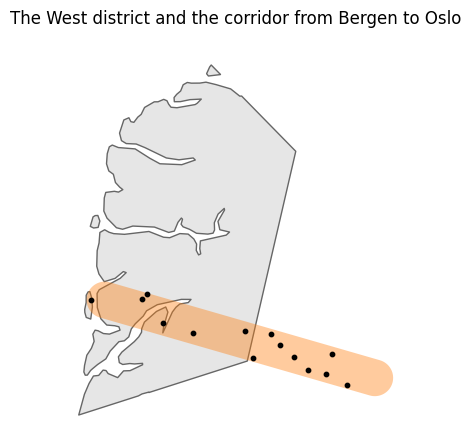

In [7]:
route = shapely.LineString([named_m.geometry.iloc[0], named_m.geometry.iloc[1]])
corridor = gpd.GeoDataFrame(geometry=[route.buffer(20_000)], crs=25833)
in_corridor = gpd.sjoin(stations_m, corridor)
fig, ax = plt.subplots(figsize=(6, 5))
districts[districts["district"] == "West"].plot(ax=ax, color="0.9", edgecolor="0.4")
corridor.plot(ax=ax, color="tab:orange", alpha=0.4)
in_corridor.plot(ax=ax, color="black", markersize=10)
ax.set_axis_off()
ax.set_title("The West district and the corridor from Bergen to Oslo")
plt.show()

The corridor runs on past the West district toward Oslo, so the map shows part of it outside the district, with the corridor's stations in both.

---

&#8592; **Back to:** [Buffers, Overlays and Clipping](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/10-buffers-overlays-and-clipping.ipynb)  &nbsp;&middot;&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)
